# 01 - Explore the data
**What this notebook does:** puts all curves on the same quarterly dates, then makes the charts that help us (and the judges) understand the data. Charts are saved in `DWC26/outputs/figures` for the PowerPoint.

**How to run:** Runtime -> Run all (about 5 minutes). Needs notebook 00 to have been run once.

Read the text under each chart: it tells you what to look for and what to write in the slides.

In [1]:
# SETUP - run this cell first, every time you open the notebook.
# It connects Google Drive, installs one extra package and loads our helper code.
import os, sys, subprocess, importlib
try:
    from google.colab import drive
    drive.mount('/content/drive')
    BASE = '/content/drive/MyDrive/DWC26'          # the shared team folder
except ImportError:                                 # (only used when running outside Colab)
    BASE = os.environ.get('DWC_BASE', 'DWC26')
subprocess.run([sys.executable, '-m', 'pip', 'install', '-q', 'python-calamine'], check=False, capture_output=True)
sys.path.insert(0, f'{BASE}/notebooks')
import numpy as np, pandas as pd, matplotlib.pyplot as plt
import dwc_utils as du; importlib.reload(du)
P = du.get_paths(BASE)
pd.set_option('display.float_format', lambda x: f'{x:,.4g}')
plt.rcParams.update({'figure.dpi': 110, 'axes.grid': True, 'grid.alpha': 0.3})
print('Ready. Project folder:', BASE)

Mounted at /content/drive
Ready. Project folder: /content/drive/MyDrive/DWC26


In [2]:
for f in ['params', 'sim_long', 'obs_long']:
    du.require(f"{P['PROC']}/{f}.parquet", 'notebook 00')
params = pd.read_parquet(f"{P['PROC']}/params.parquet")
sim = pd.read_parquet(f"{P['PROC']}/sim_long.parquet")
obs = pd.read_parquet(f"{P['PROC']}/obs_long.parquet")
print(len(params), 'cases loaded')

100 cases loaded


## Step 1 - Same dates for every case
Each case was reported on slightly different dates. We read every curve off at the same dates: the first day of every quarter (Jan, Apr, Jul, Oct) from 1998 to the end of the data. That is also the spacing of the template file. The result is a neat table: one row per case, one column per quarter.

In [3]:
grid = du.quarterly_grid(sim['date'].max())
gx = du.day_number(grid)
case_ids = params['case_id'].values
Y = {v: du.curves_on_grid(sim, case_ids, v, grid) for v in du.CUMS}
OBS = {v: du.obs_on_grid(obs, v, grid) for v in du.CUMS}
np.savez(f"{P['PROC']}/arrays.npz", grid=grid.values.astype('datetime64[D]'), case_ids=case_ids,
         **Y, **{'obs_' + v: OBS[v] for v in du.CUMS})
print(f'{len(case_ids)} cases x {len(grid)} quarters, from {grid[0].date()} to {grid[-1].date()}')

100 cases x 41 quarters, from 1998-01-01 to 2008-01-01


## Chart 1 - All 100 simulated cases vs the real field
Grey lines = the 100 simulator runs. Red dots = the real field.

**What to look for:** the red dots should sit *inside* the grey bundle. That means some combination of the 4 parameters can explain the real field, so history matching makes sense. Note that all cases are identical at the start (the wells produce at a fixed target rate) and only spread apart later. The later years carry the information.

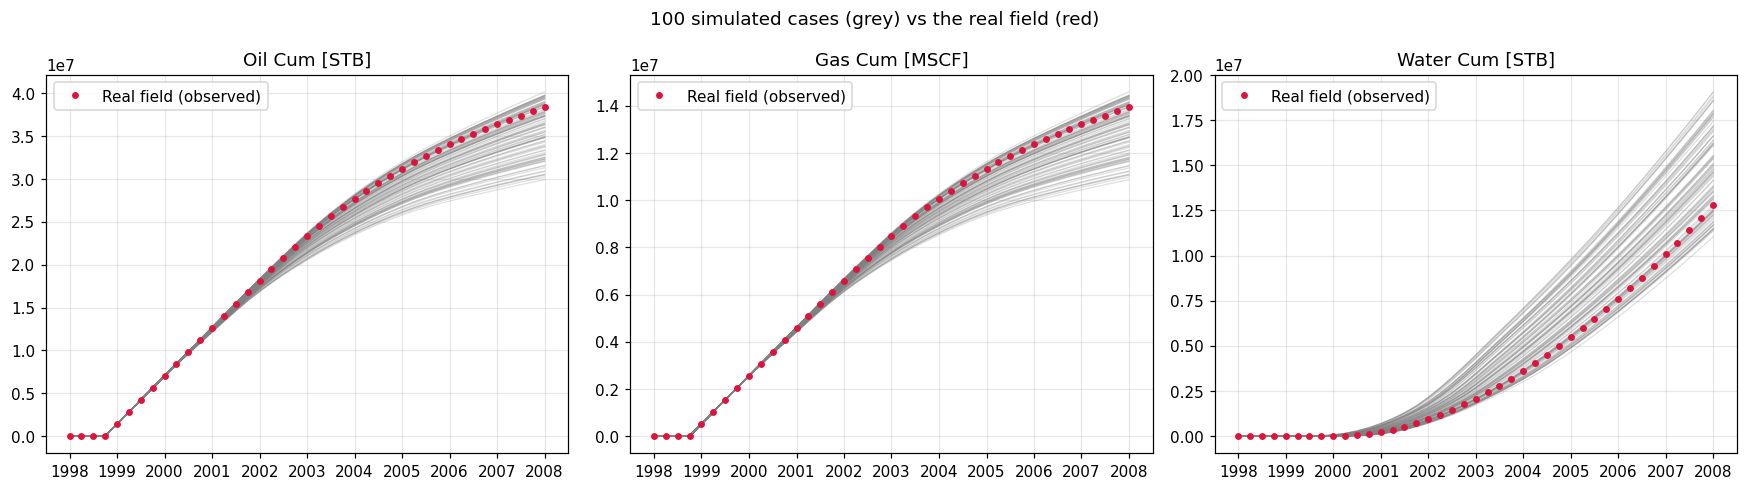

In [4]:
fig, ax = plt.subplots(1, 3, figsize=(16, 4.5))
for a, v in zip(ax, du.CUMS):
    a.plot(grid, Y[v].T, color='grey', alpha=0.25, lw=0.8)
    a.plot(grid, OBS[v], 'o', color='crimson', ms=3.5, label='Real field (observed)')
    a.set_title(v.replace('_', ' ').title() + f' [{du.UNITS[v]}]'); a.legend(loc='upper left')
fig.suptitle('100 simulated cases (grey) vs the real field (red)'); fig.tight_layout()
fig.savefig(f"{P['FIG']}/01_fan_cumulative.png", bbox_inches='tight'); plt.show()

## Chart 2 - Daily rates
Rates are calculated from the cumulative curves (change per quarter / days). You can see the **plateau** (flat early part), the **decline** (oil falling), and **water** arriving and rising. The real field again sits inside the bundle.

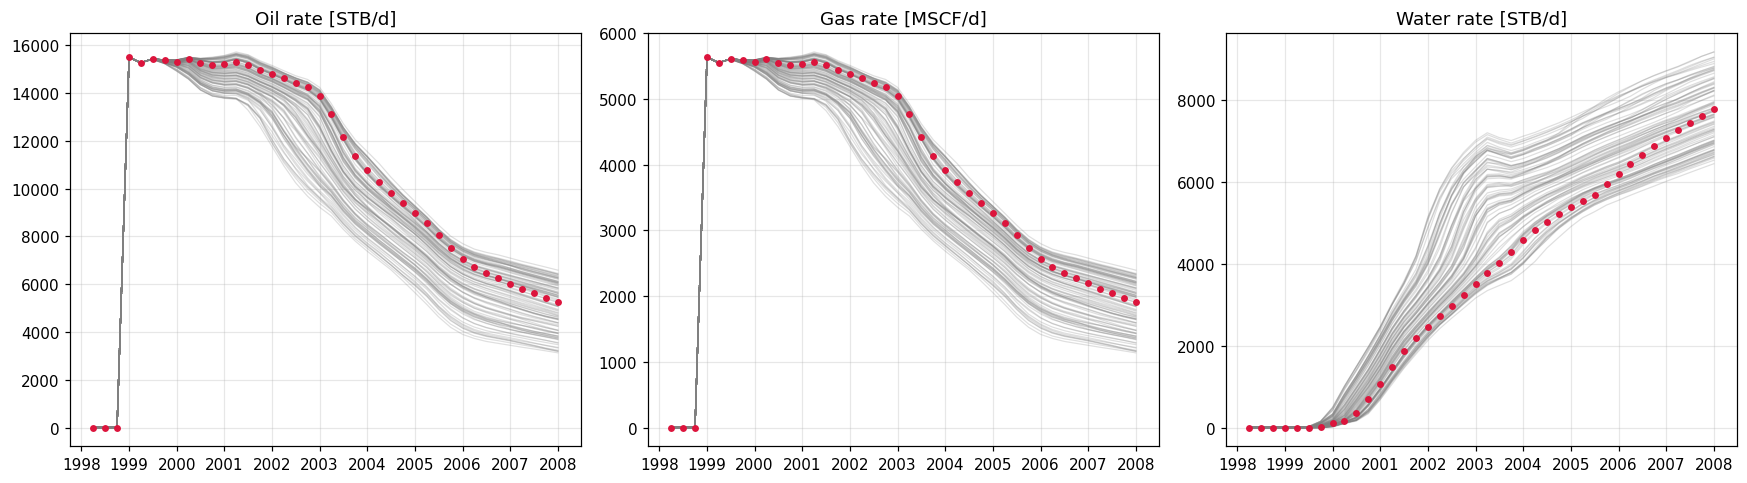

In [5]:
fig, ax = plt.subplots(1, 3, figsize=(16, 4.5))
for a, v in zip(ax, du.CUMS):
    a.plot(grid[1:], du.rates_from_cum(gx, Y[v]).T, color='grey', alpha=0.25, lw=0.8)
    a.plot(grid[1:], du.rates_from_cum(gx, OBS[v]), 'o', color='crimson', ms=3.5)
    a.set_title(v.split('_')[0].title() + f' rate [{du.UNITS[v.replace("cum", "rate")]}]')
fig.tight_layout(); fig.savefig(f"{P['FIG']}/02_fan_rates.png", bbox_inches='tight'); plt.show()

## Chart 3 - Are the 100 cases spread evenly?
Each dot is a case, placed by two of its parameters. Evenly scattered dots with no big empty areas mean the 100 runs cover all realistic possibilities. Colours show train / validation / test.

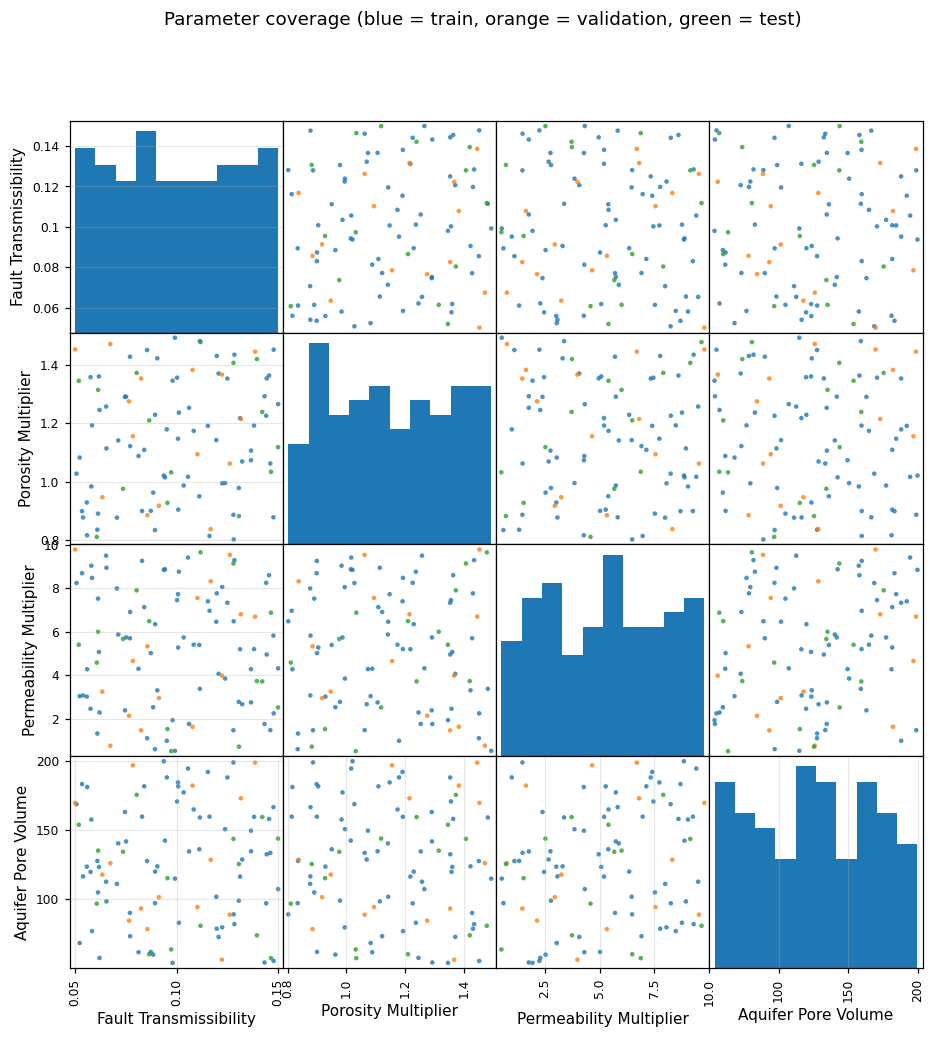

In [6]:
colors = params['split'].map({'train': 'tab:blue', 'validation': 'tab:orange', 'test': 'tab:green'})
axes = pd.plotting.scatter_matrix(params[du.PARAMS].rename(columns=du.PARAM_LABELS), c=colors, figsize=(10, 10), diagonal='hist', alpha=0.8)
plt.suptitle('Parameter coverage (blue = train, orange = validation, green = test)')
plt.savefig(f"{P['FIG']}/03_parameter_coverage.png", bbox_inches='tight'); plt.show()

## Chart 4 - Which parameter matters most?
For each parameter we measure how strongly it moves three results: oil produced by 2008, water produced by 2008, and when the plateau ends. The measure is **Spearman correlation**: +1 = when the parameter goes up, the result always goes up; -1 = always goes down; 0 = no link. The printed sentences can go straight into a slide.

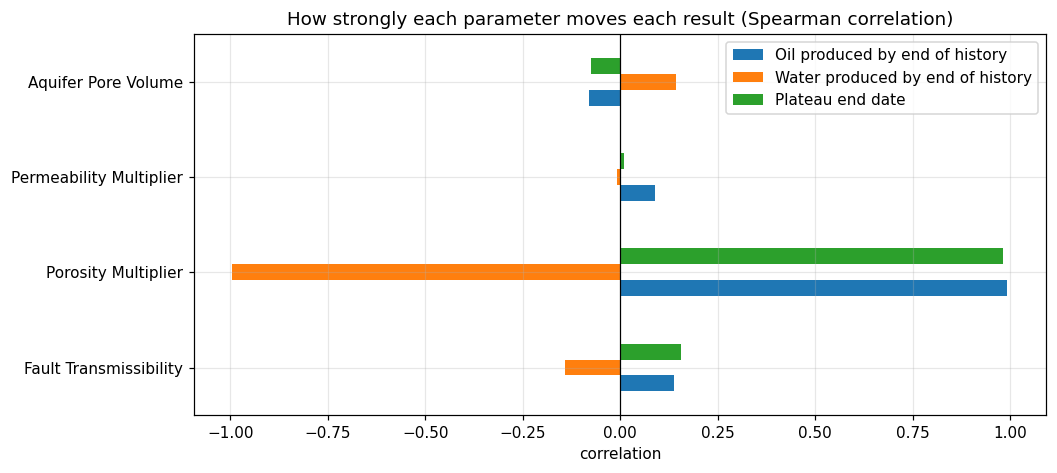

- Oil produced by end of history: driven mostly by Porosity Multiplier (correlation +0.99)
- Water produced by end of history: driven mostly by Porosity Multiplier (correlation -0.99)
- Plateau end date: driven mostly by Porosity Multiplier (correlation +0.98)


In [7]:
last = -1
plateau_end = np.array([du.decline_start(gx, Y['oil_cum'][i]) for i in range(len(case_ids))])
results = pd.DataFrame({'Oil produced by end of history': Y['oil_cum'][:, last],
                        'Water produced by end of history': Y['water_cum'][:, last],
                        'Plateau end date': plateau_end})
corr = pd.DataFrame({r: [params[p].corr(results[r], method='spearman') for p in du.PARAMS] for r in results},
                    index=[du.PARAM_LABELS[p] for p in du.PARAMS])
corr.to_csv(f"{P['OUT']}/sensitivity.csv")
corr.plot.barh(figsize=(10, 4.5)); plt.axvline(0, color='k', lw=0.8)
plt.title('How strongly each parameter moves each result (Spearman correlation)'); plt.xlabel('correlation')
plt.savefig(f"{P['FIG']}/04_sensitivity.png", bbox_inches='tight'); plt.show()
for r in corr.columns:
    top = corr[r].abs().idxmax()
    print(f'- {r}: driven mostly by {top} (correlation {corr.loc[top, r]:+.2f})')

## Check 1 - Gas follows oil (gas-oil ratio)
If gas cumulative / oil cumulative stays the same over time and across cases, we can forecast gas simply as *oil x GOR*. The numbers below should be almost identical (about 0.363 MSCF per barrel).

In [8]:
started = Y['oil_cum'] > 0
gor = np.where(started, Y['gas_cum'] / np.where(started, Y['oil_cum'], 1), np.nan)
obs_gor = OBS['gas_cum'] / np.where(OBS['oil_cum'] > 0, OBS['oil_cum'], np.nan)
print(f'Simulated cases: GOR between {np.nanmin(gor):.4f} and {np.nanmax(gor):.4f}')
print(f'Real field:      GOR between {np.nanmin(obs_gor):.4f} and {np.nanmax(obs_gor):.4f}')
print('-> Gas can be forecast as oil x GOR.' if np.nanmax(gor) - np.nanmin(gor) < 0.02 else '-> GOR changes: notebook 04 should forecast gas from its own trend.')

Simulated cases: GOR between 0.3630 and 0.3633
Real field:      GOR between 0.3633 and 0.3633
-> Gas can be forecast as oil x GOR.


## Check 2 - What the grid files tell us
Three checks using the full grid of cases 1 and 2 (saved by notebook 00):
1. **Multiplier check:** porosity of case 2 / porosity of case 1 should equal the ratio of their porosity multipliers. If so, the 4 parameters fully describe how the cases differ, which justifies using them as the model's inputs.
2. **Snapshot check:** if pressure and saturations are identical in both cases, the snapshot was taken at the start (1998), so the oil-filled pore volume is the oil originally in place.
3. **Map:** porosity and permeability of the top layer, a nice picture for the slides.

1. Porosity ratio case2/case1 = 1.1359; multiplier ratio = 1.1359 -> MATCH
2. PRESSURE: largest difference between case 1 and 2 = 0
2. SOIL: largest difference between case 1 and 2 = 0
2. SWAT: largest difference between case 1 and 2 = 0
2. SGAS: largest difference between case 1 and 2 = 0


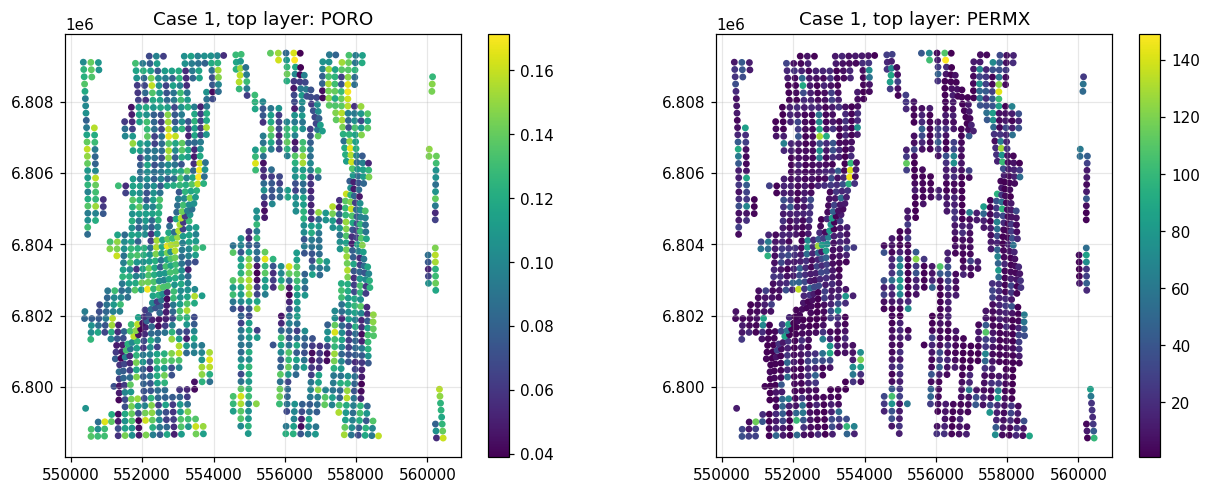

In [9]:
f1, f2 = (f"{P['PROC']}/grid_full/case_{i:03d}.parquet" for i in (1, 2))
if os.path.exists(f1) and os.path.exists(f2):
    a, b = pd.read_parquet(f1), pd.read_parquet(f2)
    act = (a['PORV'] > 0) & (b['PORV'] > 0) & a['PORO'].notna()
    ratio = (b.loc[act, 'PORO'] / a.loc[act, 'PORO']).median()
    expected = params.set_index('case_id').loc[2, 'poro_mult'] / params.set_index('case_id').loc[1, 'poro_mult']
    print(f'1. Porosity ratio case2/case1 = {ratio:.4f}; multiplier ratio = {expected:.4f} ->',
          'MATCH' if abs(ratio - expected) < 0.01 * expected else 'different - discuss with the team')
    for col in ['PRESSURE', 'SOIL', 'SWAT', 'SGAS']:
        if col in a:
            print(f'2. {col}: largest difference between case 1 and 2 = {np.nanmax(np.abs(a[col] - b[col])):.4g}')
    top = a[(a['K'] == a['K'].min()) & act]
    fig, ax = plt.subplots(1, 2, figsize=(14, 5))
    for axx, col in zip(ax, ['PORO', 'PERMX']):
        sc = axx.scatter(top['X'], top['Y'], c=top[col], s=12, cmap='viridis'); plt.colorbar(sc, ax=axx)
        axx.set_title(f'Case 1, top layer: {col}'); axx.set_aspect('equal')
    fig.savefig(f"{P['FIG']}/05_grid_map.png", bbox_inches='tight'); plt.show()
else:
    print('Full grid of cases 1 and 2 not found - run step 4 of notebook 00.')

In [10]:
gf_path = f"{P['PROC']}/grid_features.parquet"
if os.path.exists(gf_path):
    feats = pd.read_parquet(gf_path).merge(params, on='case_id')
    cols = [c for c in feats.columns if c not in du.PARAMS + ['case_id', 'split'] and feats[c].nunique() > 1]
    table = feats[du.PARAMS + cols].corr(method='spearman').loc[du.PARAMS, cols].round(2)
    table.index = [du.PARAM_LABELS[p] for p in du.PARAMS]
    print('How the grid summaries relate to the 4 parameters (1 = move together perfectly):')
    display(table)

How the grid summaries relate to the 4 parameters (1 = move together perfectly):


,pore_volume_total,oil_pore_volume,water_pore_volume,porosity_mean,permx_geomean
Fault Transmissibility,0.04,0.14,0.04,0.14,-0.05
Porosity Multiplier,0.42,1,0.42,1,-0.01
Permeability Multiplier,0.14,-0.01,0.14,-0.01,1
Aquifer Pore Volume,0.86,-0.07,0.87,-0.05,0.17


## What to put in the slides from this notebook
- Chart 1 with the sentence: *"The real field lies inside the range of the 100 simulations, so the 4 parameters can explain it."*
- Chart 4 and the printed sentences about which parameter drives what.
- The multiplier check: *"Cases differ only through 4 multipliers, so these 4 numbers are our model inputs."*
- The map, to show the reservoir.

**Next: notebook 02.**